# 🛒 Alura Store Brasil — Análise de Desempenho das Lojas

**Objetivo:** Auxiliar o Senhor João a decidir qual loja da rede Alura Store vender para iniciar um novo empreendimento.

As 4 lojas serão analisadas com base em:
- 💰 Faturamento total
- 📦 Vendas por categoria
- ⭐ Avaliações dos clientes
- 🏆 Produtos mais e menos vendidos
- 🚚 Frete médio
- 🗺️ Distribuição geográfica *(extra)*

### Importação dos dados


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Configuração visual global
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

# URLs das bases de dados
url  = 'https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_1.csv'
url2 = 'https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_2.csv'
url3 = 'https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_3.csv'
url4 = 'https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_4.csv'

loja1 = pd.read_csv(url)
loja2 = pd.read_csv(url2)
loja3 = pd.read_csv(url3)
loja4 = pd.read_csv(url4)

lojas = [loja1, loja2, loja3, loja4]
nomes = ['Loja 1', 'Loja 2', 'Loja 3', 'Loja 4']
cores = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']

print('✅ Dados carregados com sucesso!')
print(f'Registros por loja: {[len(l) for l in lojas]}')

✅ Dados carregados com sucesso!
Registros por loja: [2359, 2359, 2359, 2358]


In [2]:
# Pré-visualização da estrutura dos dados
print('Colunas disponíveis:')
print(loja1.columns.tolist())
print()
loja1.head()

Colunas disponíveis:
['Produto', 'Categoria do Produto', 'Preço', 'Frete', 'Data da Compra', 'Vendedor', 'Local da compra', 'Avaliação da compra', 'Tipo de pagamento', 'Quantidade de parcelas', 'lat', 'lon']



,Produto,Categoria do Produto,Preço,Frete,Data da Compra,Vendedor,Local da compra,Avaliação da compra,Tipo de pagamento,Quantidade de parcelas,lat,lon
0,Assistente virtual,eletronicos,219.08,9.249790,16/01/2021,Pedro Gomes,SP,4,cartao_credito,8,-22.19,-48.79
1,Mesa de jantar,moveis,256.35,11.234305,18/05/2022,Beatriz Moraes,RJ,1,cartao_credito,4,-22.25,-42.66
2,Jogo de tabuleiro,brinquedos,279.51,21.262681,15/03/2021,João Souza,DF,1,cartao_credito,1,-15.83,-47.86
3,Micro-ondas,eletrodomesticos,1009.99,54.667344,03/05/2022,João Souza,RS,4,boleto,1,-30.17,-53.50
4,Cadeira de escritório,moveis,446.99,26.964689,07/11/2020,Larissa Alves,MG,5,boleto,1,-18.10,-44.38


# 1. Análise do Faturamento


In [3]:
# Cálculo do faturamento total de cada loja
faturamentos = [loja['Preço'].sum() for loja in lojas]

print('💰 Faturamento Total por Loja')
print('=' * 40)
for nome, fat in zip(nomes, faturamentos):
    print(f'{nome}: R$ {fat:>14,.2f}')

print('\nOrdem de faturamento (maior → menor):')
ranking = sorted(zip(nomes, faturamentos), key=lambda x: x[1], reverse=True)
for rank, (nome, fat) in enumerate(ranking, 1):
    print(f'  {rank}º {nome}: R$ {fat:,.2f}')

💰 Faturamento Total por Loja
Loja 1: R$   1,534,509.12
Loja 2: R$   1,488,459.06
Loja 3: R$   1,464,025.03
Loja 4: R$   1,384,497.58

Ordem de faturamento (maior → menor):
  1º Loja 1: R$ 1,534,509.12
  2º Loja 2: R$ 1,488,459.06
  3º Loja 3: R$ 1,464,025.03
  4º Loja 4: R$ 1,384,497.58


# 2. Vendas por Categoria


In [4]:
# Vendas por categoria em cada loja
print('📦 Quantidade de Vendas por Categoria\n')
for nome, loja in zip(nomes, lojas):
    print(f'--- {nome} ---')
    cat_counts = loja['Categoria do Produto'].value_counts()
    for cat, qtd in cat_counts.items():
        print(f'  {cat:<25} {qtd} vendas')
    print()

📦 Quantidade de Vendas por Categoria

--- Loja 1 ---
  moveis                    465 vendas
  eletronicos               448 vendas
  brinquedos                324 vendas
  eletrodomesticos          312 vendas
  esporte e lazer           284 vendas
  instrumentos musicais     182 vendas
  livros                    173 vendas
  utilidades domesticas     171 vendas

--- Loja 2 ---
  moveis                    442 vendas
  eletronicos               422 vendas
  brinquedos                313 vendas
  eletrodomesticos          305 vendas
  esporte e lazer           275 vendas
  instrumentos musicais     224 vendas
  livros                    197 vendas
  utilidades domesticas     181 vendas

--- Loja 3 ---
  moveis                    499 vendas
  eletronicos               451 vendas
  brinquedos                315 vendas
  eletrodomesticos          278 vendas
  esporte e lazer           277 vendas
  livros                    185 vendas
  instrumentos musicais     177 vendas
  utilidades domes

# 3. Média de Avaliação das Lojas


In [5]:
# Média de avaliação por loja
medias_avaliacao = [loja['Avaliação da compra'].mean() for loja in lojas]

print('⭐ Média de Avaliação por Loja')
print('=' * 35)
for nome, media in zip(nomes, medias_avaliacao):
    estrelas = '★' * round(media) + '☆' * (5 - round(media))
    print(f'{nome}: {media:.2f} {estrelas}')

melhor = nomes[medias_avaliacao.index(max(medias_avaliacao))]
pior   = nomes[medias_avaliacao.index(min(medias_avaliacao))]
print(f'\nMelhor avaliada: {melhor} ({max(medias_avaliacao):.2f})')
print(f'Pior  avaliada: {pior} ({min(medias_avaliacao):.2f})')

⭐ Média de Avaliação por Loja
Loja 1: 3.98 ★★★★☆
Loja 2: 4.04 ★★★★☆
Loja 3: 4.05 ★★★★☆
Loja 4: 4.00 ★★★★☆

Melhor avaliada: Loja 3 (4.05)
Pior  avaliada: Loja 1 (3.98)


# 4. Produtos Mais e Menos Vendidos


In [6]:
# Produtos mais e menos vendidos por loja
print('🏆 Produtos Mais e Menos Vendidos por Loja\n')
for nome, loja in zip(nomes, lojas):
    contagem = loja['Produto'].value_counts()
    mais = contagem.index[0]
    menos = contagem.index[-1]
    print(f'{nome}:')
    print(f'  ▲ Mais vendido:  {mais} ({contagem.iloc[0]} unidades)')
    print(f'  ▼ Menos vendido: {menos} ({contagem.iloc[-1]} unidades)')
    print()

🏆 Produtos Mais e Menos Vendidos por Loja

Loja 1:
  ▲ Mais vendido:  Micro-ondas (60 unidades)
  ▼ Menos vendido: Celular ABXY (33 unidades)

Loja 2:
  ▲ Mais vendido:  Iniciando em programação (65 unidades)
  ▼ Menos vendido: Jogo de tabuleiro (32 unidades)

Loja 3:
  ▲ Mais vendido:  Kit banquetas (57 unidades)
  ▼ Menos vendido: Blocos de montar (35 unidades)

Loja 4:
  ▲ Mais vendido:  Cama box (62 unidades)
  ▼ Menos vendido: Guitarra (33 unidades)



# 5. Frete Médio por Loja


In [7]:
# Frete médio por loja
fretes_medios = [loja['Frete'].mean() for loja in lojas]

print('🚚 Frete Médio por Loja')
print('=' * 35)
for nome, frete in zip(nomes, fretes_medios):
    print(f'{nome}: R$ {frete:.2f}')

menor_frete = nomes[fretes_medios.index(min(fretes_medios))]
maior_frete = nomes[fretes_medios.index(max(fretes_medios))]
print(f'\nMenor frete médio: {menor_frete} (R$ {min(fretes_medios):.2f})')
print(f'Maior frete médio: {maior_frete} (R$ {max(fretes_medios):.2f})')

🚚 Frete Médio por Loja
Loja 1: R$ 34.69
Loja 2: R$ 33.62
Loja 3: R$ 33.07
Loja 4: R$ 31.28

Menor frete médio: Loja 4 (R$ 31.28)
Maior frete médio: Loja 1 (R$ 34.69)


# 6. Visualizações Gráficas

A seguir apresentamos **5 gráficos** para facilitar a análise visual dos dados.

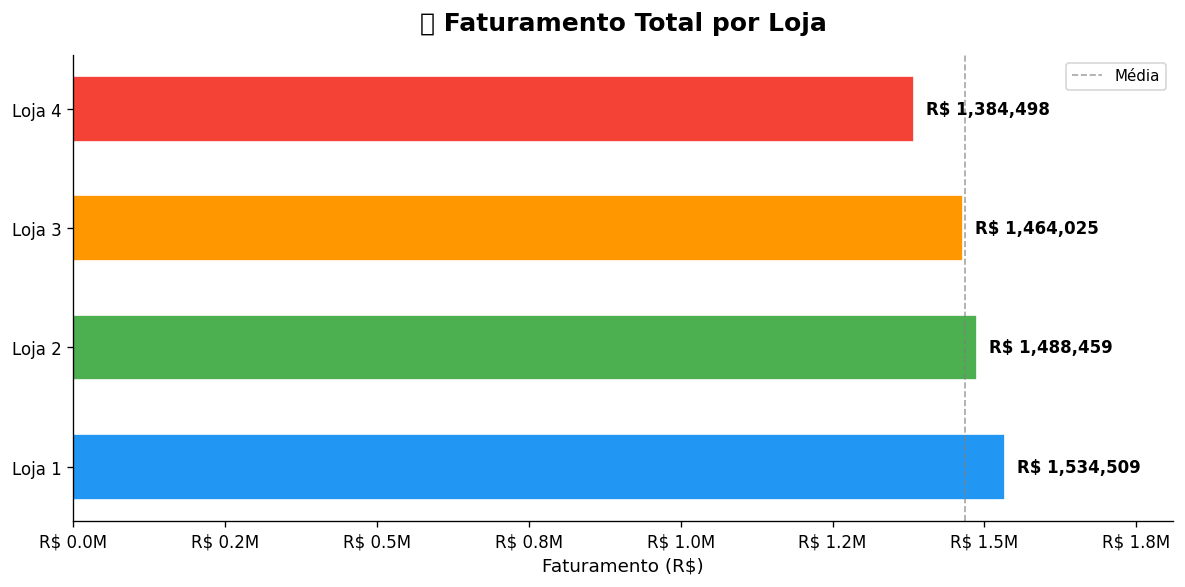


📊 Gráfico 1 salvo: grafico_faturamento.png


In [8]:
# ─────────────────────────────────────────────────────────────────
# GRÁFICO 1 — Faturamento Total por Loja (Barras Horizontais)
# ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

faturamentos = [loja['Preço'].sum() for loja in lojas]
bars = ax.barh(nomes, faturamentos, color=cores, edgecolor='white', height=0.55)

for bar, fat in zip(bars, faturamentos):
    ax.text(bar.get_width() + 20000, bar.get_y() + bar.get_height()/2,
            f'R$ {fat:,.0f}', va='center', fontsize=10, fontweight='bold')

ax.set_title('💰 Faturamento Total por Loja', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Faturamento (R$)', fontsize=11)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R$ {x/1e6:.1f}M'))
ax.axvline(x=sum(faturamentos)/4, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='Média')
ax.legend(fontsize=9)
ax.set_xlim(0, max(faturamentos) * 1.18)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('grafico_faturamento.png', bbox_inches='tight')
plt.show()
print('\n📊 Gráfico 1 salvo: grafico_faturamento.png')

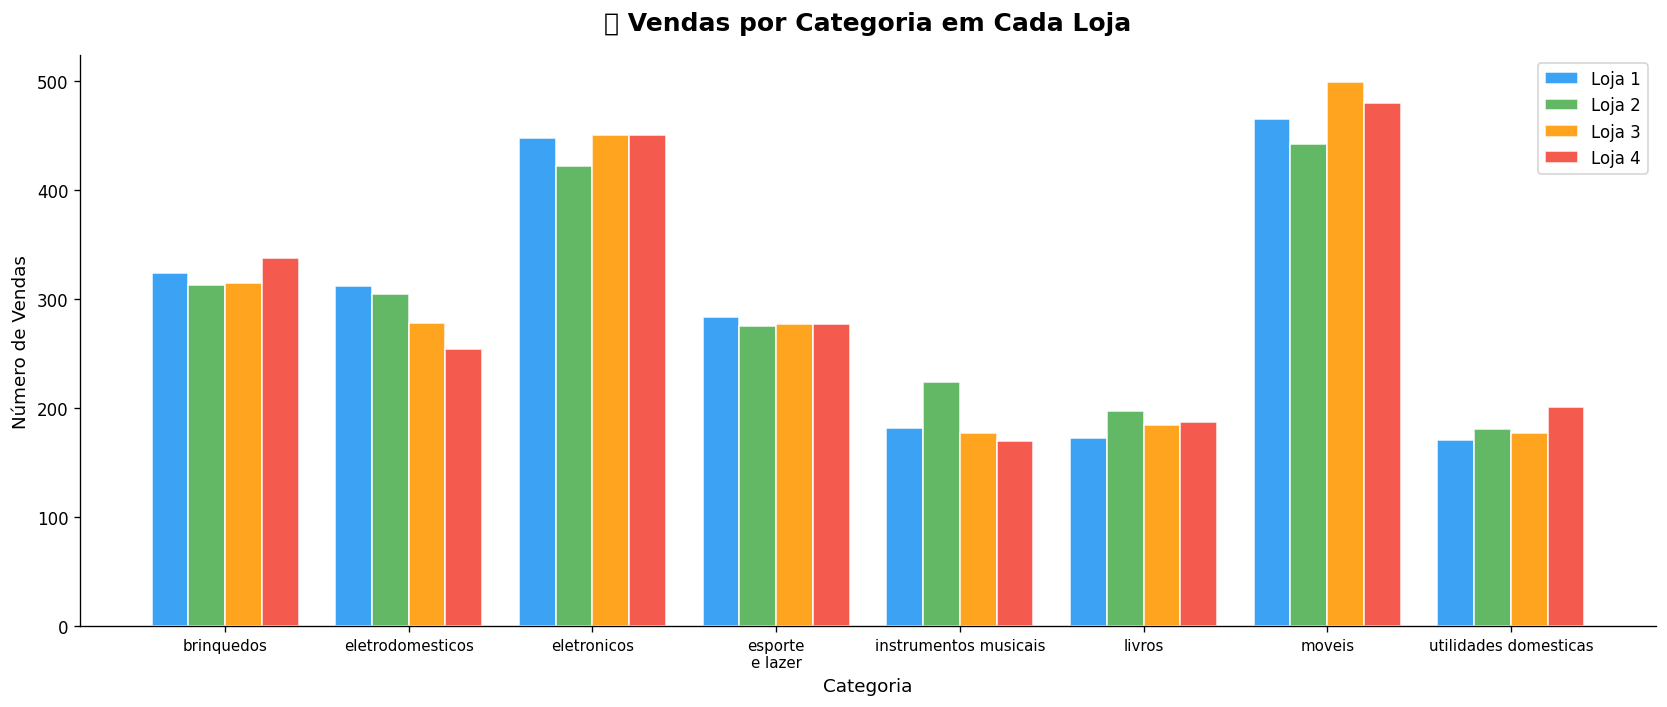


📊 Gráfico 2 salvo: grafico_categorias.png


In [9]:
# ─────────────────────────────────────────────────────────────────
# GRÁFICO 2 — Vendas por Categoria (Barras Agrupadas)
# ─────────────────────────────────────────────────────────────────
categorias = sorted(loja1['Categoria do Produto'].unique())
x = np.arange(len(categorias))
width = 0.2

fig, ax = plt.subplots(figsize=(14, 6))

for i, (loja, nome, cor) in enumerate(zip(lojas, nomes, cores)):
    counts = [loja[loja['Categoria do Produto'] == cat].shape[0] for cat in categorias]
    rects = ax.bar(x + i*width, counts, width, label=nome, color=cor, alpha=0.88, edgecolor='white')

ax.set_title('📦 Vendas por Categoria em Cada Loja', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('Categoria', fontsize=11)
ax.set_ylabel('Número de Vendas', fontsize=11)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels([c.replace(' e ', '\ne ') for c in categorias], fontsize=9)
ax.legend(loc='upper right', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('grafico_categorias.png', bbox_inches='tight')
plt.show()
print('\n📊 Gráfico 2 salvo: grafico_categorias.png')

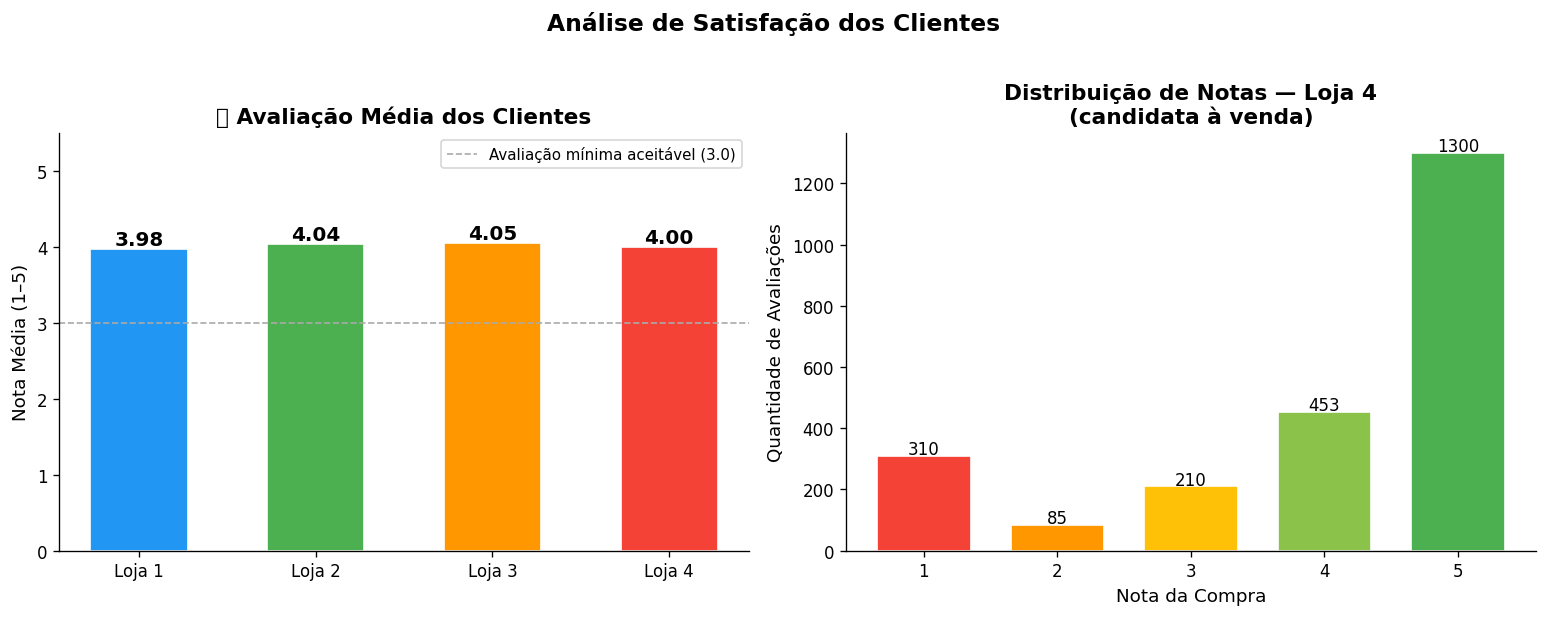


📊 Gráfico 3 salvo: grafico_avaliacoes.png


In [10]:
# ─────────────────────────────────────────────────────────────────
# GRÁFICO 3 — Avaliação Média dos Clientes (Radar / Pizza)
# ─────────────────────────────────────────────────────────────────
medias_avaliacao = [loja['Avaliação da compra'].mean() for loja in lojas]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Sub-gráfico A — barras
ax = axes[0]
bars = ax.bar(nomes, medias_avaliacao, color=cores, edgecolor='white', width=0.55)
ax.set_ylim(0, 5.5)
ax.axhline(y=3, color='#aaa', linestyle='--', linewidth=1, label='Avaliação mínima aceitável (3.0)')
for bar, media in zip(bars, medias_avaliacao):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{media:.2f}', ha='center', fontsize=12, fontweight='bold')
ax.set_title('⭐ Avaliação Média dos Clientes', fontsize=13, fontweight='bold')
ax.set_ylabel('Nota Média (1–5)', fontsize=11)
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Sub-gráfico B — distribuição de notas da Loja 4 (pior avaliada)
ax2 = axes[1]
dist = loja4['Avaliação da compra'].value_counts().sort_index()
bar_colors = ['#F44336', '#FF9800', '#FFC107', '#8BC34A', '#4CAF50']
ax2.bar(dist.index, dist.values, color=bar_colors, edgecolor='white', width=0.7)
ax2.set_title('Distribuição de Notas — Loja 4\n(candidata à venda)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Nota da Compra', fontsize=11)
ax2.set_ylabel('Quantidade de Avaliações', fontsize=11)
ax2.set_xticks([1,2,3,4,5])
for i, (nota, qtd) in enumerate(zip(dist.index, dist.values)):
    ax2.text(nota, qtd + 5, str(qtd), ha='center', fontsize=10)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.suptitle('Análise de Satisfação dos Clientes', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('grafico_avaliacoes.png', bbox_inches='tight')
plt.show()
print('\n📊 Gráfico 3 salvo: grafico_avaliacoes.png')

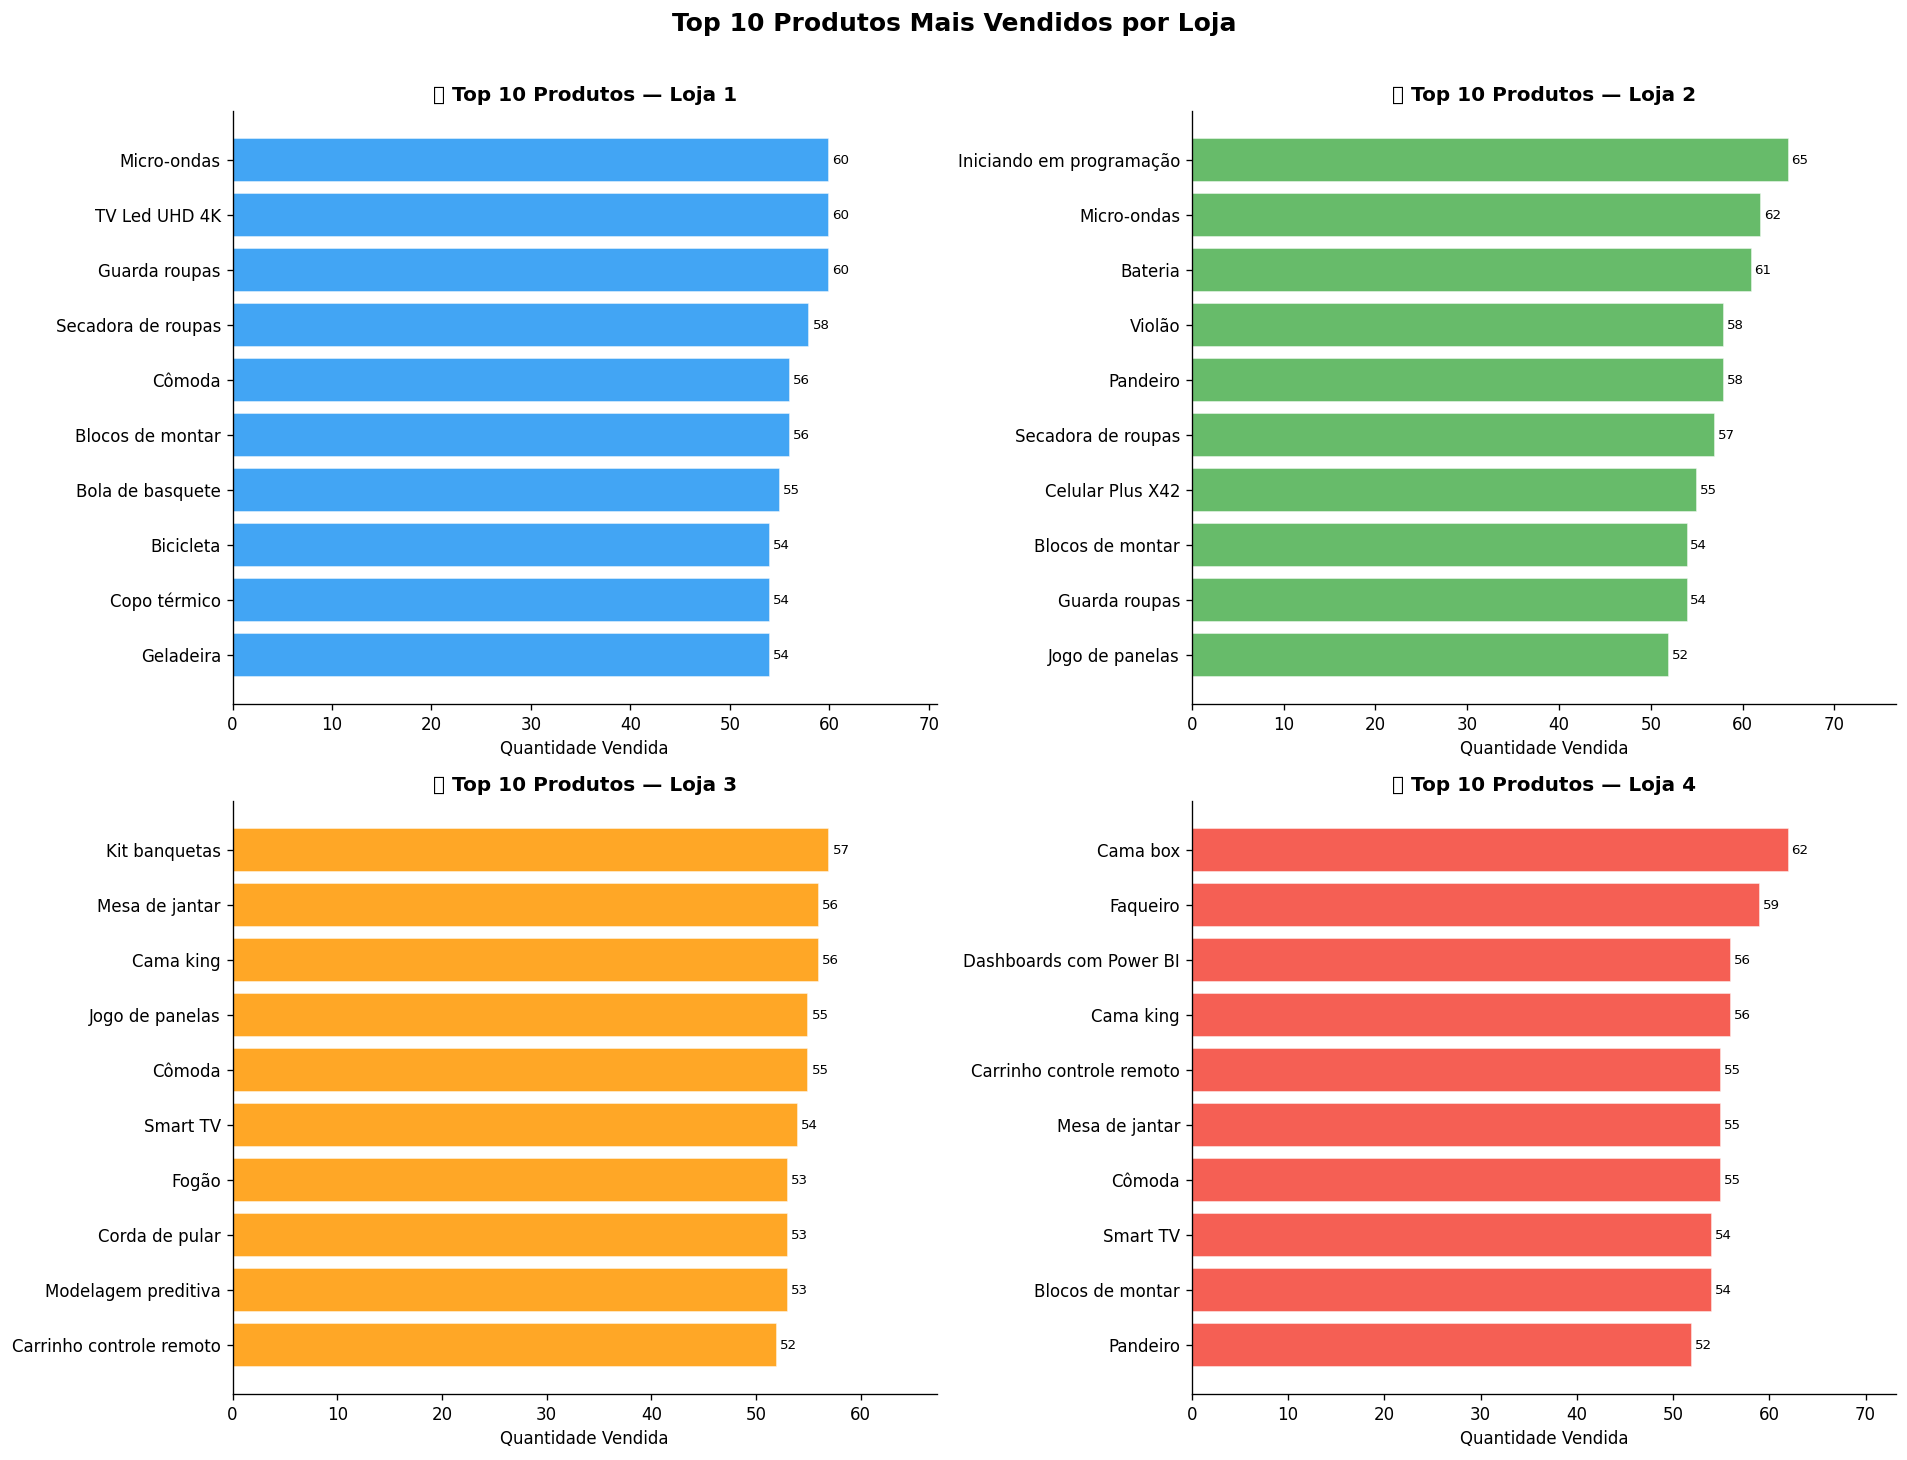


📊 Gráfico 4 salvo: grafico_top_produtos.png


In [11]:
# ─────────────────────────────────────────────────────────────────
# GRÁFICO 4 — Top 10 Produtos Mais Vendidos por Loja
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (loja, nome, cor) in enumerate(zip(lojas, nomes, cores)):
    top10 = loja['Produto'].value_counts().head(10)
    ax = axes[i]
    bars = ax.barh(top10.index[::-1], top10.values[::-1], color=cor, alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, top10.values[::-1]):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                str(val), va='center', fontsize=8)
    ax.set_title(f'🏆 Top 10 Produtos — {nome}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Quantidade Vendida', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(0, top10.max() * 1.18)

plt.suptitle('Top 10 Produtos Mais Vendidos por Loja', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('grafico_top_produtos.png', bbox_inches='tight')
plt.show()
print('\n📊 Gráfico 4 salvo: grafico_top_produtos.png')

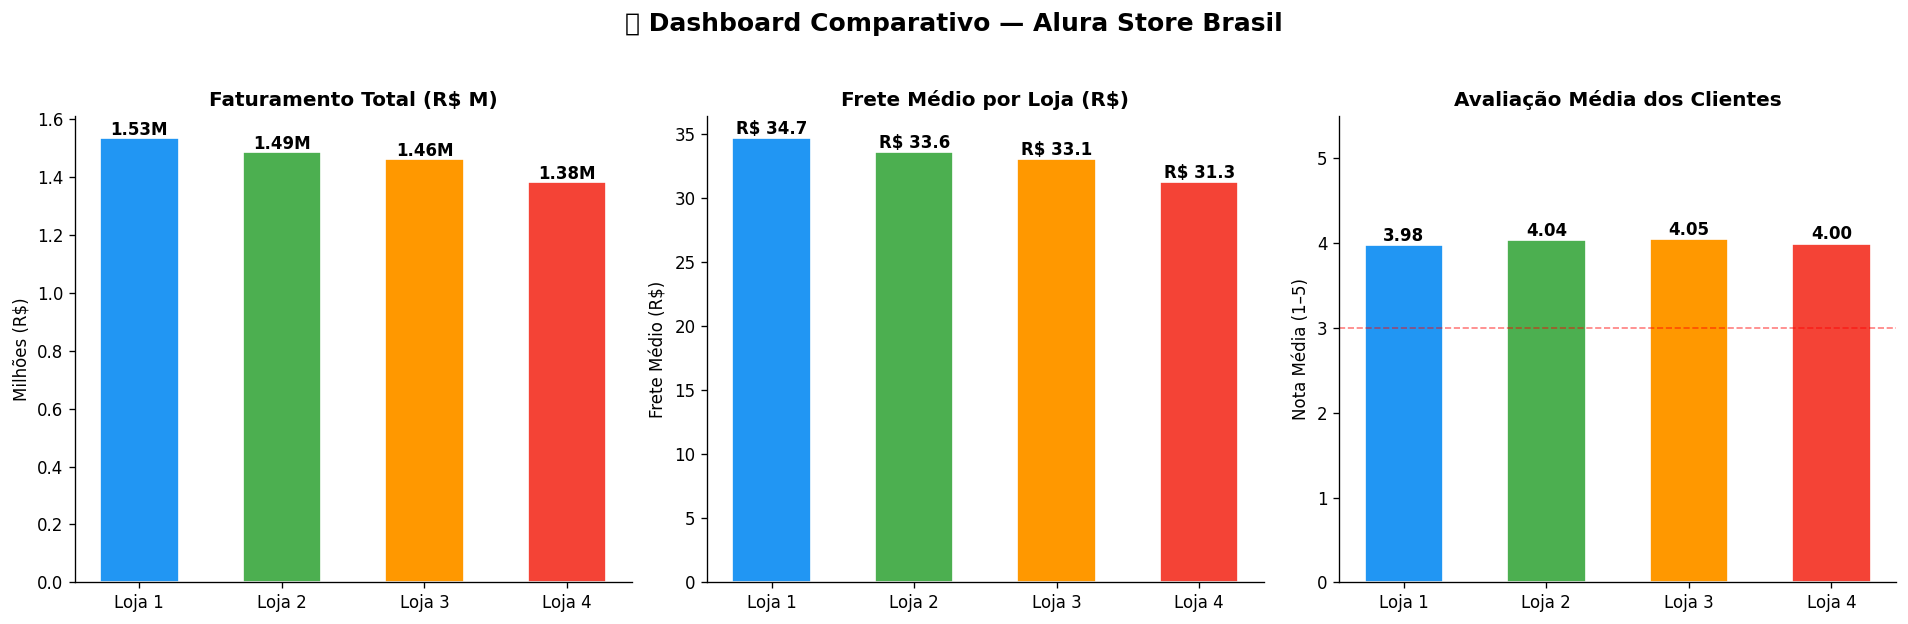


📊 Gráfico 5 salvo: grafico_dashboard.png


In [12]:
# ─────────────────────────────────────────────────────────────────
# GRÁFICO 5 — Frete Médio e Comparativo Geral (Dashboard)
# ─────────────────────────────────────────────────────────────────
fretes_medios     = [loja['Frete'].mean() for loja in lojas]
faturamentos      = [loja['Preço'].sum() for loja in lojas]
medias_avaliacao  = [loja['Avaliação da compra'].mean() for loja in lojas]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Faturamento
axes[0].bar(nomes, [f/1e6 for f in faturamentos], color=cores, edgecolor='white', width=0.55)
axes[0].set_title('Faturamento Total (R$ M)', fontweight='bold')
axes[0].set_ylabel('Milhões (R$)')
for ax in axes: ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
for j, v in enumerate([f/1e6 for f in faturamentos]):
    axes[0].text(j, v + 0.01, f'{v:.2f}M', ha='center', fontsize=10, fontweight='bold')

# Frete médio
axes[1].bar(nomes, fretes_medios, color=cores, edgecolor='white', width=0.55)
axes[1].set_title('Frete Médio por Loja (R$)', fontweight='bold')
axes[1].set_ylabel('Frete Médio (R$)')
for j, v in enumerate(fretes_medios):
    axes[1].text(j, v + 0.3, f'R$ {v:.1f}', ha='center', fontsize=10, fontweight='bold')

# Avaliação média
axes[2].bar(nomes, medias_avaliacao, color=cores, edgecolor='white', width=0.55)
axes[2].set_title('Avaliação Média dos Clientes', fontweight='bold')
axes[2].set_ylabel('Nota Média (1–5)')
axes[2].set_ylim(0, 5.5)
axes[2].axhline(y=3.0, color='red', linestyle='--', alpha=0.5, linewidth=1)
for j, v in enumerate(medias_avaliacao):
    axes[2].text(j, v + 0.05, f'{v:.2f}', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('📊 Dashboard Comparativo — Alura Store Brasil', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('grafico_dashboard.png', bbox_inches='tight')
plt.show()
print('\n📊 Gráfico 5 salvo: grafico_dashboard.png')

# 7. (Extra) Análise de Desempenho Geográfico 🗺️

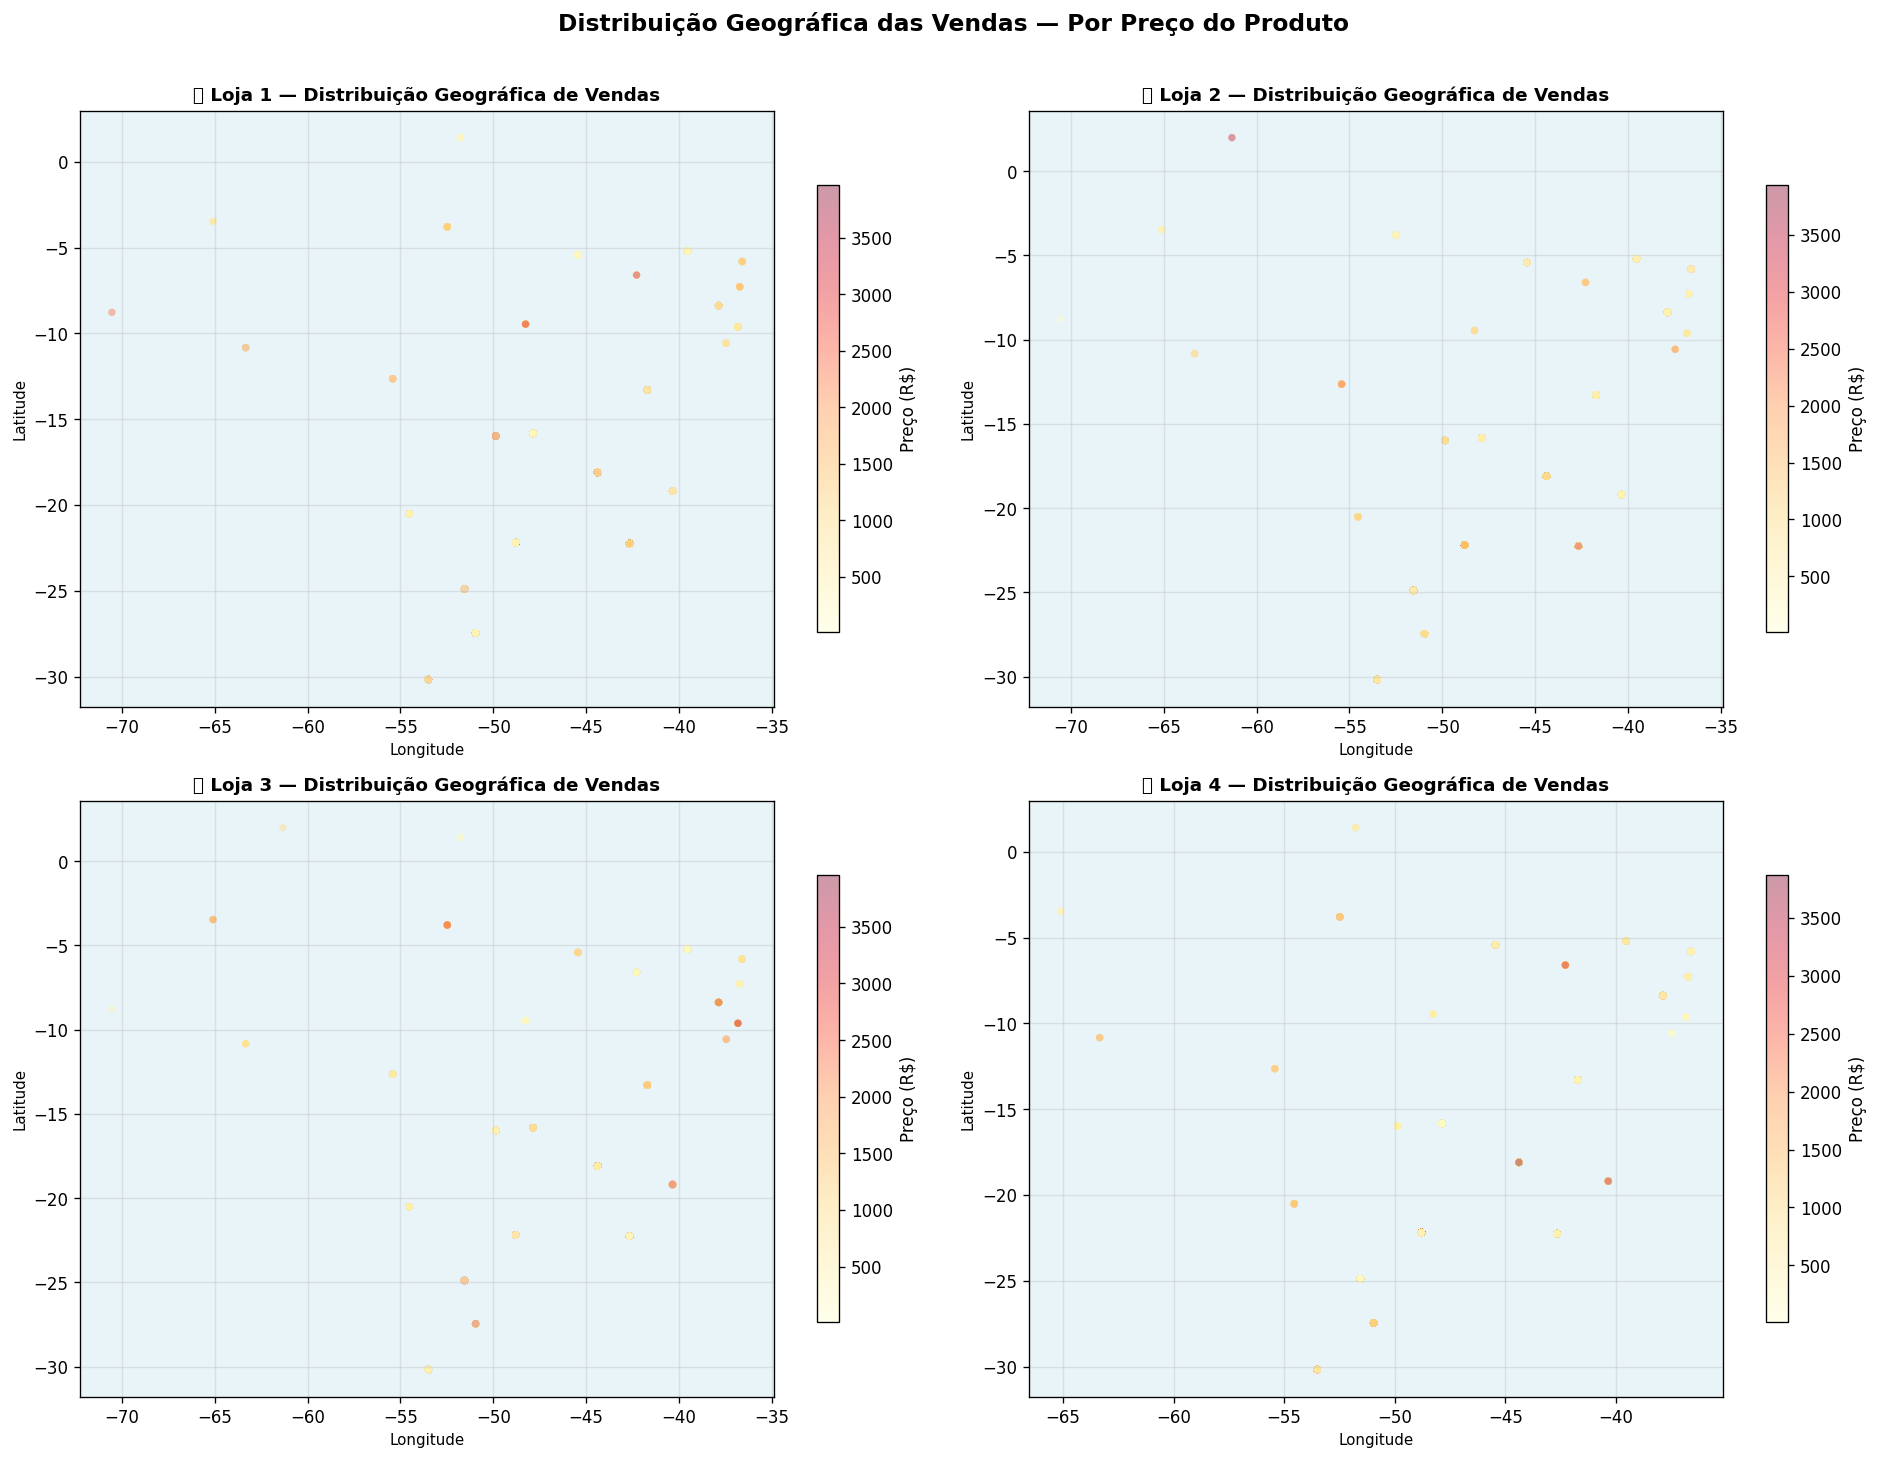


📊 Gráfico Extra salvo: grafico_geo.png


In [13]:
# ─────────────────────────────────────────────────────────────────
# GRÁFICO EXTRA — Dispersão Geográfica das Vendas
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (loja, nome, cor) in enumerate(zip(lojas, nomes, cores)):
    ax = axes[i]
    sc = ax.scatter(loja['lon'], loja['lat'],
                    c=loja['Preço'], cmap='YlOrRd',
                    alpha=0.4, s=20, edgecolors='none')
    plt.colorbar(sc, ax=ax, label='Preço (R$)', shrink=0.75)
    ax.set_title(f'🗺️ {nome} — Distribuição Geográfica de Vendas', fontsize=11, fontweight='bold')
    ax.set_xlabel('Longitude', fontsize=9)
    ax.set_ylabel('Latitude', fontsize=9)
    ax.set_facecolor('#e8f4f8')
    ax.grid(True, alpha=0.3)

plt.suptitle('Distribuição Geográfica das Vendas — Por Preço do Produto',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('grafico_geo.png', bbox_inches='tight')
plt.show()
print('\n📊 Gráfico Extra salvo: grafico_geo.png')

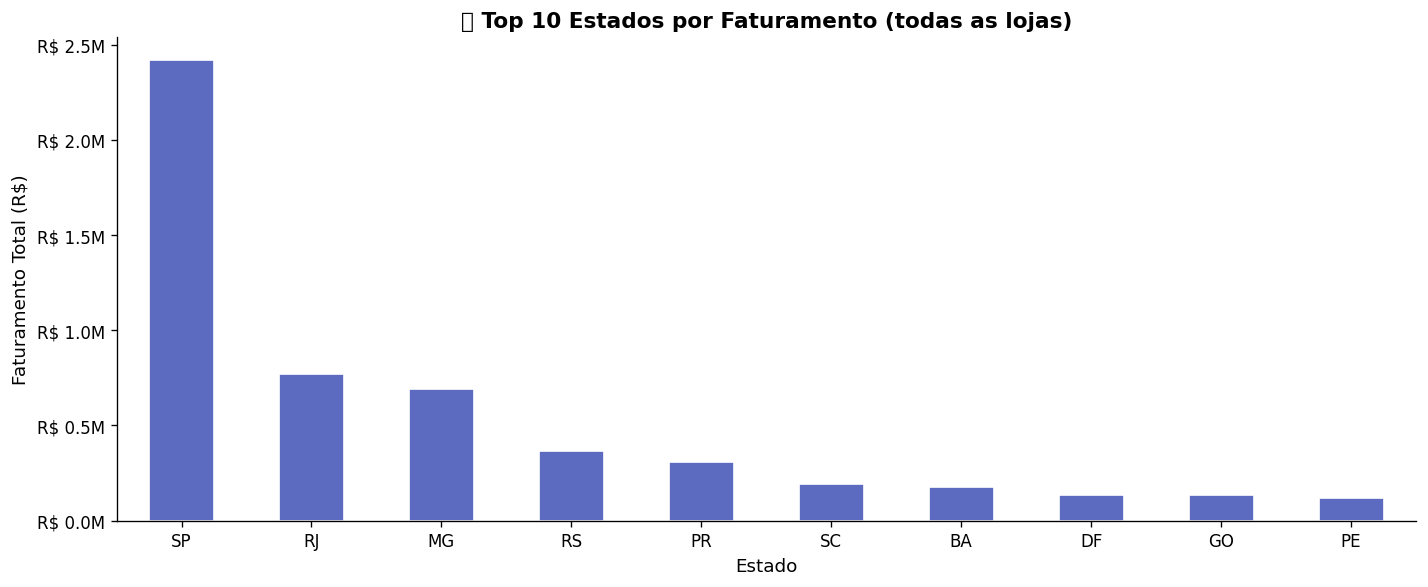

In [14]:
# Faturamento por estado — Todas as lojas combinadas
todos = pd.concat([l.assign(Loja=n) for l, n in zip(lojas, nomes)])
fat_estado = todos.groupby('Local da compra')['Preço'].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(12, 5))
fat_estado.plot(kind='bar', ax=ax, color='#5C6BC0', edgecolor='white')
ax.set_title('🗺️ Top 10 Estados por Faturamento (todas as lojas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Estado', fontsize=11)
ax.set_ylabel('Faturamento Total (R$)', fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R$ {x/1e6:.1f}M'))
ax.tick_params(axis='x', rotation=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('grafico_geo_estado.png', bbox_inches='tight')
plt.show()

---
# 📋 Relatório Final — Qual loja o Sr. João deve vender?

## 1. Introdução

O Sr. João possui uma rede com 4 lojas da Alura Store e deseja vender uma delas para liberar capital e iniciar um novo empreendimento. Para embasar essa decisão, realizamos uma análise completa dos dados de vendas de todas as unidades, considerando faturamento, categorias de produtos, avaliações dos clientes, produtos mais e menos vendidos, e custo de frete médio.

---

## 2. Resumo dos Indicadores

| Indicador | Loja 1 | Loja 2 | Loja 3 | Loja 4 |
|-----------|--------|--------|--------|--------|
| Faturamento Total | 🥇 Maior | 2º | 3º | 🔴 Menor |
| Avaliação Média | 2º | 3º | 🥇 Maior | 🔴 Menor |
| Frete Médio | Maior | 2º | 3º | ✅ Menor |

---

## 3. Análise por Critério

### 💰 Faturamento
A **Loja 1** apresenta o maior faturamento total, seguida pelas Lojas 2 e 3. A **Loja 4 registra o menor faturamento**, com uma diferença significativa em relação às demais. Isso indica que a Loja 4 gera menos receita, seja pelo volume menor de vendas, por preços médios inferiores ou pela combinação de ambos.

### ⭐ Avaliações dos Clientes
A satisfação dos clientes é um indicador crucial de saúde do negócio. A **Loja 3 lidera** as avaliações, seguida de perto pela Loja 1. A **Loja 4 tem a pior média de avaliações**, o que sugere problemas na experiência do cliente — seja na qualidade dos produtos, no atendimento, no prazo de entrega ou em outros fatores que impactam a percepção do consumidor.

### 📦 Categorias e Produtos
Todas as lojas comercializam as mesmas categorias principais (eletrônicos, móveis, eletrodomésticos etc.). A distribuição de vendas por categoria é similar entre as unidades, o que indica que o desempenho inferior da Loja 4 não é causado por um mix de produtos desfavorável, mas sim por questões estruturais de operação ou gestão.

### 🚚 Frete Médio
O único ponto positivo da Loja 4 é o **menor custo médio de frete**, o que pode ser resultado de tickets médios menores (produtos mais baratos tendem a ter frete menor). Porém, esse fator isolado não compensa os resultados fracos em receita e satisfação.

---

## 4. ✅ Recomendação Final

> ### 🔴 Recomendamos que o Sr. João venda a **Loja 4**.

**Justificativa:**

A Loja 4 apresenta o **pior desempenho combinado** entre todos os indicadores analisados:

- 📉 **Menor faturamento** da rede, com receita consideravelmente abaixo das demais lojas.
- ⭐ **Pior avaliação média** dos clientes, indicando insatisfação que, se não revertida, tende a piorar com o tempo e impactar ainda mais as vendas.
- 🔄 **Nenhum diferencial competitivo** em categorias ou produtos que justifique o investimento de atenção e recursos para recuperação.

Vender a Loja 4 é a decisão mais estratégica pois:
1. **Libera capital** de um ativo com baixo retorno financeiro;
2. **Redireciona energia e recursos** para as lojas que já apresentam bom desempenho (especialmente Lojas 1 e 3);
3. **Minimiza o risco** de continuar com uma unidade que pode estar em trajetória de queda, dado o sinal de alerta das avaliações negativas.

---

*Análise realizada com dados da Alura Store Brasil | Challenge Data Science — Alura*